# HAM10000 - Lesion-Safe Train / Validation / Test Split

## Protocol locked for the current project

- Dataset: HAM10000
- Working task: 7-class skin lesion classification
- Source rows: 10,015 images
- Unique lesions: 7,470
- Multi-image lesions: 1,956
- Split unit: `lesion_id`
- Target split: 70% / 15% / 15% by lesion
- Random seed: 42
- Required final leakage evidence:

```text
Train join Validation = 0
Train join Test = 0
Validation join Test = 0
```

### What this notebook proves

1. Multiple HAM10000 images can belong to the same `lesion_id`.
2. Lesions are the unit being split.
3. Every image inherits the split of its lesion.
4. Whole-lesion assignments remain isolated across train/validation/test.
5. A reproducible split manifest is saved for later training/evaluation.

> **Important:** The 70/15/15 target is defined on lesion groups. Because a lesion may have multiple images, image counts are a consequence of group assignment. This notebook also rebalances whole lesion groups within diagnosis classes so the current project image totals are reproduced without ever splitting a lesion across partitions.

In [42]:
# Core imports and reproducibility settings
from pathlib import Path
import json
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split

RANDOM_SEED = 42

# Point this to the original HAM10000 metadata file.
# Examples:
#   Path("HAM10000_metadata.csv")
#   Path("/content/HAM10000_metadata.csv")
#   Path("/content/drive/MyDrive/HAM10000/HAM10000_metadata.csv")
METADATA_PATH = Path(
    os.getenv("HAM10000_METADATA_PATH", "../dataset/HAM10000_metadata.csv")
)

OUTPUT_DIR = Path(
    os.getenv("HAM10000_SPLIT_OUTPUT_DIR", "output-d.u")
)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

SPLITS = ["train", "val", "test"]
TARGET_LESION_RATIOS = {"train": 0.70, "val": 0.15, "test": 0.15}

# These are the image totals of the current prepared project protocol.
# They are targets for the whole-lesion rebalancing step.
EXPECTED_IMAGE_COUNTS = {
    "train": 7002,
    "val": 1532,
    "test": 1481,
}

EXPECTED_LESION_COUNTS = {
    "train": 5229,
    "val": 1120,
    "test": 1121,
}

CLASS_LABELS = {
    "nv": "melanocytic nevi",
    "mel": "melanoma",
    "bkl": "benign keratosis-like lesions",
    "bcc": "basal cell carcinoma",
    "akiec": "actinic keratoses / intraepidermal carcinoma",
    "vasc": "vascular lesions",
    "df": "dermatofibroma",
}

## 1. Load and validate HAM10000 metadata

In [43]:
if not METADATA_PATH.exists():
    # Helpful path hints without scanning the whole filesystem.
    candidates = [
        Path("HAM10000_metadata.csv"),
        Path("/content/HAM10000_metadata.csv"),
        Path("/content/drive/MyDrive/HAM10000/HAM10000_metadata.csv"),
        Path("/content/drive/MyDrive/HAM10000/HAM10000/HAM10000_metadata.csv"),
    ]
    existing = [p for p in candidates if p.exists()]
    if existing:
        METADATA_PATH = existing[0]
    else:
        raise FileNotFoundError(
            f"Could not find HAM10000_metadata.csv. "
            f"Set METADATA_PATH to the actual file path. Checked: {candidates}"
        )

df = pd.read_csv(METADATA_PATH)

REQUIRED_COLUMNS = {"image_id", "lesion_id", "dx"}
missing = REQUIRED_COLUMNS - set(df.columns)
assert not missing, f"Missing required columns: {sorted(missing)}"

df = df.copy()
df["image_id"] = df["image_id"].astype(str)
df["lesion_id"] = df["lesion_id"].astype(str)
df["dx"] = df["dx"].astype(str).str.lower()

print(f"Metadata path: {METADATA_PATH}")
print(f"Rows (images): {len(df):,}")
print(f"Unique image_id: {df['image_id'].nunique():,}")
print(f"Unique lesion_id: {df['lesion_id'].nunique():,}")
display(df.head())

# Present-1 data-integrity assertions from the project's audited HAM10000 facts.
assert len(df) == 10015, f"Expected 10,015 rows, got {len(df):,}"
assert df["image_id"].nunique() == 10015, "image_id must be unique"
assert df["lesion_id"].nunique() == 7470, "Expected 7,470 unique lesions"

Metadata path: ..\dataset\HAM10000_metadata.csv
Rows (images): 10,015
Unique image_id: 10,015
Unique lesion_id: 7,470


,lesion_id,image_id,dx,dx_type,age,sex,localization,dataset
0,HAM_0000118,ISIC_0027419,bkl,histo,80.0,male,scalp,vidir_modern
1,HAM_0000118,ISIC_0025030,bkl,histo,80.0,male,scalp,vidir_modern
2,HAM_0002730,ISIC_0026769,bkl,histo,80.0,male,scalp,vidir_modern
3,HAM_0002730,ISIC_0025661,bkl,histo,80.0,male,scalp,vidir_modern
4,HAM_0001466,ISIC_0031633,bkl,histo,75.0,male,ear,vidir_modern


## 2. Demonstrate that multiple images can belong to one lesion

In [44]:
images_per_lesion = (
    df.groupby("lesion_id")
      .size()
      .rename("image_count")
      .sort_values(ascending=False)
)

multi_image_lesions = images_per_lesion[images_per_lesion > 1]

print(f"Lesions with >= 2 images: {len(multi_image_lesions):,}")
assert len(multi_image_lesions) == 1956, (
    f"Expected 1,956 multi-image lesions, got {len(multi_image_lesions):,}"
)

display(
    df[df["lesion_id"].isin(multi_image_lesions.index)]
      .sort_values(["lesion_id", "image_id"])
      [["image_id", "lesion_id", "dx"]]
      .head(20)
)

display(
    multi_image_lesions.rename_axis("lesion_id").reset_index()
        .head(15)
)

Lesions with >= 2 images: 1,956


,image_id,lesion_id,dx
9188,ISIC_0025346,HAM_0000000,nv
9187,ISIC_0028498,HAM_0000000,nv
1661,ISIC_0032622,HAM_0000002,mel
1660,ISIC_0033848,HAM_0000002,mel
1662,ISIC_0034246,HAM_0000002,mel
9900,ISIC_0024579,HAM_0000005,akiec
9898,ISIC_0025577,HAM_0000005,akiec
9901,ISIC_0029638,HAM_0000005,akiec
9899,ISIC_0030591,HAM_0000005,akiec
1517,ISIC_0032187,HAM_0000006,mel


,lesion_id,image_count
0,HAM_0000835,6
1,HAM_0005263,6
2,HAM_0003789,6
3,HAM_0001863,6
4,HAM_0007427,5
5,HAM_0000893,5
6,HAM_0007367,5
7,HAM_0007343,5
8,HAM_0002364,5
9,HAM_0006469,4


### Why this matters

The rows above show that one `lesion_id` can correspond to multiple image records.

Therefore, splitting individual image rows independently can place related images from the same lesion into different partitions. The safe unit for this protocol is the lesion group.

## 3. Build one row per lesion

In [45]:
# Each lesion must have exactly one ground-truth diagnostic class in this metadata.
dx_per_lesion = df.groupby("lesion_id")["dx"].nunique()
bad_lesions = dx_per_lesion[dx_per_lesion != 1]
assert bad_lesions.empty, (
    "Some lesion_id values have multiple dx labels; inspect the metadata before splitting."
)

lesion_df = (
    df.groupby("lesion_id", as_index=False)
      .agg(
          dx=("dx", "first"),
          n_images=("image_id", "size"),
      )
)

print(f"Lesion-level rows: {len(lesion_df):,}")
display(lesion_df.head())

assert len(lesion_df) == 7470
assert lesion_df["lesion_id"].is_unique

Lesion-level rows: 7,470


,lesion_id,dx,n_images
0,HAM_0000000,nv,2
1,HAM_0000001,bkl,1
2,HAM_0000002,mel,3
3,HAM_0000003,nv,1
4,HAM_0000004,nv,1


## 4. Create the split at lesion level

The first split uses `train_test_split(..., stratify=dx, random_state=42)` on the lesion table:

1. 70% of lesions -> train
2. 30% of lesions -> temporary pool
3. 50% of the temporary pool -> validation
4. 50% of the temporary pool -> test

In [46]:
train_lesions, temp_lesions = train_test_split(
    lesion_df,
    test_size=0.30,
    stratify=lesion_df["dx"],
    random_state=RANDOM_SEED,
)

val_lesions, test_lesions = train_test_split(
    temp_lesions,
    test_size=0.50,
    stratify=temp_lesions["dx"],
    random_state=RANDOM_SEED,
)

lesion_assignments = pd.concat(
    [
        train_lesions.assign(split="train"),
        val_lesions.assign(split="val"),
        test_lesions.assign(split="test"),
    ],
    ignore_index=True,
)

print(
    lesion_assignments["split"]
        .value_counts()
        .reindex(SPLITS)
        .to_string()
)

lesion_count_check = (
    lesion_assignments.groupby("split")
        .size()
        .reindex(SPLITS)
)

display(lesion_count_check.rename("lesions").to_frame())

for split, expected in EXPECTED_LESION_COUNTS.items():
    assert int(lesion_count_check[split]) == expected, (
        f"{split}: expected {expected} lesions, got {int(lesion_count_check[split])}"
    )

# No lesion can be assigned twice.
assert lesion_assignments["lesion_id"].nunique() == 7470
assert not lesion_assignments["lesion_id"].duplicated().any()

split
train    5229
val      1120
test     1121


,lesions
split,
train,5229
val,1120
test,1121


## 5. Rebalance image totals using whole-lesion swaps

A multi-image lesion contributes more than one image row. The adjustment below does not move images individually. It swaps entire lesions of the same diagnosis class between splits.  
This preserves:

- lesion-level separation,
- the number of lesions in each split,
- diagnosis counts at the lesion level,

In [47]:
def rebalance_image_counts(
    lesion_table: pd.DataFrame,
    target_image_counts: dict,
    seed: int = 42,
    max_iter: int = 1000,
):
    """Adjust image totals by swapping whole lesions within the same dx class."""
    work = lesion_table.copy()
    rng = np.random.default_rng(seed)
    work["_tie_break"] = rng.random(len(work))

    split_names = list(target_image_counts)
    image_counts = (
        work.groupby("split")["n_images"]
            .sum()
            .reindex(split_names)
            .astype(int)
            .to_dict()
    )

    for iteration in range(max_iter):
        if all(
            image_counts[s] == target_image_counts[s]
            for s in split_names
        ):
            return work.drop(columns="_tie_break"), iteration

        excess_splits = [
            s for s in split_names
            if image_counts[s] > target_image_counts[s]
        ]
        deficit_splits = [
            s for s in split_names
            if image_counts[s] < target_image_counts[s]
        ]

        # Only the lesion-size buckets are enumerated; this avoids an expensive
        # pairwise scan over all lesions.
        bucket = (
            work.groupby(["split", "dx", "n_images"], sort=False)
                .agg(
                    count=("lesion_id", "size"),
                    min_tie=("_tie_break", "min"),
                )
        )
        available_sizes = sorted(work["n_images"].unique().tolist())
        available_dx = list(work["dx"].unique())

        candidates = []

        for donor in excess_splits:
            for recipient in deficit_splits:
                donor_surplus = (
                    image_counts[donor] - target_image_counts[donor]
                )
                recipient_need = (
                    target_image_counts[recipient] - image_counts[recipient]
                )
                max_transfer = min(donor_surplus, recipient_need)

                for dx in available_dx:
                    for donor_size in available_sizes:
                        d_key = (donor, dx, donor_size)
                        if d_key not in bucket.index:
                            continue

                        for recipient_size in available_sizes:
                            r_key = (recipient, dx, recipient_size)
                            if r_key not in bucket.index:
                                continue

                            transfer = int(donor_size - recipient_size)
                            if transfer <= 0 or transfer > max_transfer:
                                continue

                            candidate_error = 0
                            for split_name in split_names:
                                value = image_counts[split_name]
                                if split_name == donor:
                                    value -= transfer
                                elif split_name == recipient:
                                    value += transfer
                                candidate_error += abs(
                                    value - target_image_counts[split_name]
                                )

                            candidates.append(
                                (
                                    candidate_error,
                                    -transfer,
                                    float(
                                        bucket.loc[d_key, "min_tie"]
                                        + bucket.loc[r_key, "min_tie"]
                                    ),
                                    donor,
                                    recipient,
                                    dx,
                                    donor_size,
                                    recipient_size,
                                )
                            )

        if not candidates:
            raise RuntimeError(
                "Could not reach the requested image totals while preserving "
                "whole-lesion and same-class swaps. "
                f"Current counts: {image_counts}"
            )

        candidates.sort(key=lambda x: x[:3])
        (
            _,
            _,
            _,
            donor,
            recipient,
            dx,
            donor_size,
            recipient_size,
        ) = candidates[0]

        donor_mask = (
            (work["split"] == donor)
            & (work["dx"] == dx)
            & (work["n_images"] == donor_size)
        )
        recipient_mask = (
            (work["split"] == recipient)
            & (work["dx"] == dx)
            & (work["n_images"] == recipient_size)
        )

        donor_id = (
            work.loc[donor_mask]
                .sort_values("_tie_break")
                .iloc[0]["lesion_id"]
        )
        recipient_id = (
            work.loc[recipient_mask]
                .sort_values("_tie_break")
                .iloc[0]["lesion_id"]
        )

        work.loc[work["lesion_id"] == donor_id, "split"] = recipient
        work.loc[work["lesion_id"] == recipient_id, "split"] = donor

        transfer = int(donor_size - recipient_size)
        image_counts[donor] -= transfer
        image_counts[recipient] += transfer

    raise RuntimeError(
        f"Reached max_iter={max_iter} without exact image totals."
    )


lesion_assignments, iterations = rebalance_image_counts(
    lesion_assignments,
    target_image_counts=EXPECTED_IMAGE_COUNTS,
    seed=RANDOM_SEED,
)

print(f"Whole-lesion rebalance iterations: {iterations}")

Whole-lesion rebalance iterations: 6


## 6. Propagate lesion assignments back to the 10,015 image rows

In [48]:
manifest = df.merge(
    lesion_assignments[["lesion_id", "split"]],
    on="lesion_id",
    how="left",
    validate="many_to_one",
)

assert len(manifest) == len(df)
assert manifest["split"].notna().all()

# Every image appears exactly once, and every image inherits one split from its lesion.
assert manifest["image_id"].is_unique
assert manifest["lesion_id"].nunique() == 7470

display(
    manifest[["image_id", "lesion_id", "dx", "split"]]
        .head(15)
)

,image_id,lesion_id,dx,split
0,ISIC_0027419,HAM_0000118,bkl,train
1,ISIC_0025030,HAM_0000118,bkl,train
2,ISIC_0026769,HAM_0002730,bkl,train
3,ISIC_0025661,HAM_0002730,bkl,train
4,ISIC_0031633,HAM_0001466,bkl,train
5,ISIC_0027850,HAM_0001466,bkl,train
6,ISIC_0029176,HAM_0002761,bkl,test
7,ISIC_0029068,HAM_0002761,bkl,test
8,ISIC_0025837,HAM_0005132,bkl,test
9,ISIC_0025209,HAM_0005132,bkl,test


## 7. Verify split sizes and class distribution

In [49]:
split_summary = (
    manifest.groupby("split")
        .agg(
            images=("image_id", "size"),
            lesions=("lesion_id", "nunique"),
        )
        .reindex(SPLITS)
)

split_summary["lesion_ratio_pct"] = (
    100 * split_summary["lesions"] / split_summary["lesions"].sum()
)

display(split_summary.round({"lesion_ratio_pct": 2}))

# Exact project targets
for split in SPLITS:
    assert int(split_summary.loc[split, "lesions"]) == EXPECTED_LESION_COUNTS[split]
    assert int(split_summary.loc[split, "images"]) == EXPECTED_IMAGE_COUNTS[split]

class_by_split = (
    pd.crosstab(manifest["split"], manifest["dx"])
      .reindex(index=SPLITS, columns=CLASS_LABELS.keys(), fill_value=0)
)

print("Images per split x diagnostic class:")
display(class_by_split)

print("Total images:", int(split_summary["images"].sum()))
print("Total lesions:", int(split_summary["lesions"].sum()))

,images,lesions,lesion_ratio_pct
split,,,
train,7002,5229,70.00
val,1532,1120,14.99
test,1481,1121,15.01


Images per split x diagnostic class:


dx,nv,mel,bkl,bcc,akiec,vasc,df
split,,,,,,,
train,4695,778,776,361,222,99,71
val,1018,173,160,82,53,22,24
test,992,162,163,71,52,21,20


Total images: 10015
Total lesions: 7470


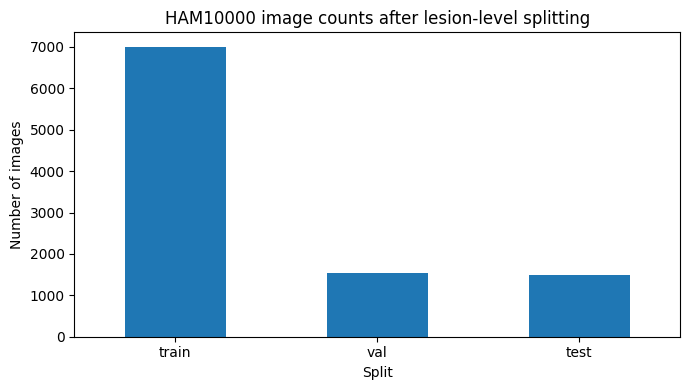

In [50]:
# Compact visual evidence for Present 1
ax = split_summary["images"].plot(
    kind="bar",
    figsize=(7, 4),
)
ax.set_title("HAM10000 image counts after lesion-level splitting")
ax.set_xlabel("Split")
ax.set_ylabel("Number of images")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 9. Present 1 Evidence

### 9.1 Prove the lesion-safe split with code

In [51]:
train_lesion_ids = set(manifest.loc[manifest["split"] == "train", "lesion_id"])
val_lesion_ids = set(manifest.loc[manifest["split"] == "val", "lesion_id"])
test_lesion_ids = set(manifest.loc[manifest["split"] == "test", "lesion_id"])

train_val_overlap = train_lesion_ids & val_lesion_ids
train_test_overlap = train_lesion_ids & test_lesion_ids
val_test_overlap = val_lesion_ids & test_lesion_ids

assert len(train_val_overlap) == 0
assert len(train_test_overlap) == 0
assert len(val_test_overlap) == 0

print(f"Train join Validation = {len(train_val_overlap)}")
print(f"Train join Test = {len(train_test_overlap)}")
print(f"Validation join Test = {len(val_test_overlap)}")

# Exact format requested for the Present 1 evidence slide.
assert "Train join Validation = 0"
assert "Train join Test = 0"
assert "Validation join Test = 0"

Train join Validation = 0
Train join Test = 0
Validation join Test = 0


### Interpretation

The three intersection checks are performed on `lesion_id` sets, not on image IDs.

Therefore, a multi-image lesion cannot contribute an image to one partition and another image to a different partition under this manifest.

### 9.2 Prove the seven classes and their image counts from ground-truth labels

The seven diagnostic classes are not hard-coded as the source of the result. The class list and counts below are derived directly from the ground-truth `dx` column in `HAM10000_metadata.csv`.

The mapping from the short `dx` code to the full diagnostic class name is only for presentation; the counts themselves come from the ground-truth labels.

In [52]:
# Ground-truth evidence: derive the seven classes and image counts directly from df["dx"].
ground_truth_counts = (
    df["dx"]
    .value_counts()
    .rename_axis("dx")
    .reset_index(name="images")
)

ground_truth_counts["class_name"] = ground_truth_counts["dx"].map(CLASS_LABELS)

ground_truth_counts = ground_truth_counts[["dx", "class_name", "images"]]

display(ground_truth_counts)

# These are the seven labels observed in the ground-truth metadata.
expected_class_codes = set(CLASS_LABELS.keys())
observed_class_codes = set(ground_truth_counts["dx"])

assert observed_class_codes == expected_class_codes, (
    f"Unexpected ground-truth class codes: {sorted(observed_class_codes)}"
)
assert len(observed_class_codes) == 7
assert int(ground_truth_counts["images"].sum()) == 10015

# Reconciliation against the project's audited dataset counts.
# The observed values above are still produced from df["dx"].value_counts().
expected_ground_truth_counts = {
    "nv": 6705,
    "mel": 1113,
    "bkl": 1099,
    "bcc": 514,
    "akiec": 327,
    "vasc": 142,
    "df": 115,
}

observed_ground_truth_counts = (
    ground_truth_counts.set_index("dx")["images"].to_dict()
)

assert observed_ground_truth_counts == expected_ground_truth_counts

print("Ground-truth class codes:", sorted(observed_class_codes))
print("Ground-truth class count total:", int(ground_truth_counts["images"].sum()))
print("PASS - seven classes and all image counts are reproduced directly from the ground-truth dx labels.")

,dx,class_name,images
0,nv,melanocytic nevi,6705
1,mel,melanoma,1113
2,bkl,benign keratosis-like lesions,1099
3,bcc,basal cell carcinoma,514
4,akiec,actinic keratoses / intraepidermal carcinoma,327
5,vasc,vascular lesions,142
6,df,dermatofibroma,115


Ground-truth class codes: ['akiec', 'bcc', 'bkl', 'df', 'mel', 'nv', 'vasc']
Ground-truth class count total: 10015
PASS - seven classes and all image counts are reproduced directly from the ground-truth dx labels.


**Present 1 interpretation**

> Ground-truth labels define the seven classes. Counting those labels gives the number of training images in each class.

This is stronger evidence than manually typing the class counts into a slide because the displayed values are generated from the dataset itself.

## 10. Final consistency checks

In [53]:
# One row per image and one split per image.
assert manifest["image_id"].nunique() == 10015
assert manifest["image_id"].is_unique
assert manifest["split"].isin(SPLITS).all()

# Every lesion is wholly assigned to exactly one split.
lesion_split_counts = manifest.groupby("lesion_id")["split"].nunique()
assert (lesion_split_counts == 1).all()

# The split totals reconcile exactly.
assert int(manifest.shape[0]) == sum(EXPECTED_IMAGE_COUNTS.values())
assert int(manifest["lesion_id"].nunique()) == sum(EXPECTED_LESION_COUNTS.values())

print("PASS - all final integrity checks succeeded.")

PASS - all final integrity checks succeeded.


## 11. Save the reproducible split manifest

In [54]:
manifest_path = OUTPUT_DIR / "HAM10000_lesion_safe_split_seed42.csv"
summary_path = OUTPUT_DIR / "HAM10000_lesion_safe_split_summary_seed42.csv"
checks_path = OUTPUT_DIR / "HAM10000_lesion_safe_split_checks_seed42.json"
class_counts_path = OUTPUT_DIR / "HAM10000_ground_truth_class_counts.csv"

manifest_to_save = manifest[
    ["image_id", "lesion_id", "dx", "split"]
].sort_values(["split", "image_id"])

manifest_to_save.to_csv(manifest_path, index=False)
ground_truth_counts.to_csv(class_counts_path, index=False)

split_summary.reset_index().rename(
    columns={"index": "split"}
).to_csv(summary_path, index=False)

checks = {
    "metadata_rows": int(len(df)),
    "unique_image_ids": int(df["image_id"].nunique()),
    "unique_lesions": int(df["lesion_id"].nunique()),
    "multi_image_lesions": int(len(multi_image_lesions)),
    "random_seed": RANDOM_SEED,
    "split_unit": "lesion_id",
    "target_lesion_ratio": TARGET_LESION_RATIOS,
    "image_counts": {
        split: int(split_summary.loc[split, "images"])
        for split in SPLITS
    },
    "lesion_counts": {
        split: int(split_summary.loc[split, "lesions"])
        for split in SPLITS
    },
    "ground_truth_class_counts": observed_ground_truth_counts,
    "lesion_overlap": {
        "train_val": len(train_val_overlap),
        "train_test": len(train_test_overlap),
        "val_test": len(val_test_overlap),
    },
}

checks_path.write_text(
    json.dumps(checks, indent=2),
    encoding="utf-8",
)

print(f"Saved manifest : {manifest_path.resolve()}")
print(f"Saved summary  : {summary_path.resolve()}")
print(f"Saved checks   : {checks_path.resolve()}")
print(f"Saved classes  : {class_counts_path.resolve()}")

display(manifest_to_save.head(10))

Saved manifest : D:\AI\Kì 5\DSR301m\Skin-Lesion-Classification\data-understanding\output-d.u\HAM10000_lesion_safe_split_seed42.csv
Saved summary  : D:\AI\Kì 5\DSR301m\Skin-Lesion-Classification\data-understanding\output-d.u\HAM10000_lesion_safe_split_summary_seed42.csv
Saved checks   : D:\AI\Kì 5\DSR301m\Skin-Lesion-Classification\data-understanding\output-d.u\HAM10000_lesion_safe_split_checks_seed42.json
Saved classes  : D:\AI\Kì 5\DSR301m\Skin-Lesion-Classification\data-understanding\output-d.u\HAM10000_ground_truth_class_counts.csv


,image_id,lesion_id,dx,split
4349,ISIC_0024306,HAM_0000550,nv,test
6803,ISIC_0024314,HAM_0002198,nv,test
4957,ISIC_0024320,HAM_0005039,nv,test
4211,ISIC_0024321,HAM_0003511,nv,test
5372,ISIC_0024326,HAM_0001812,nv,test
664,ISIC_0024336,HAM_0006732,bkl,test
997,ISIC_0024337,HAM_0005136,bkl,test
6997,ISIC_0024340,HAM_0001160,nv,test
2869,ISIC_0024345,HAM_0006872,bcc,test
382,ISIC_0024358,HAM_0000933,bkl,test


## 12. Present 1 takeaway

### Evidence 9.1 — Lesion-safe split

> **We did not split 10,015 image rows directly. We first split lesion groups, then assigned every image according to its `lesion_id`.**

The leakage test therefore checks lesion IDs across partitions:

```text
Train ∩ Validation = 0
Train ∩ Test = 0
Validation ∩ Test = 0
```

### Evidence 9.2 — Seven classes from ground truth

> **The seven classes and their image counts are obtained directly from `df["dx"].value_counts()`, not manually entered.**

The saved manifest and class-count table should be reused by later training/evaluation code so that the protocol and label distribution do not silently change.



## Source / project note

Project protocol and tracked dataset facts are aligned with the current project master summary and SSOT workbook.

Original HAM10000 dataset source:

Tschandl, P., Rosendahl, C., & Kittler, H. (2018). *The HAM10000 dataset, a large collection of multi-source dermatoscopic images of common pigmented skin lesions*. Scientific Data, 5, 180161.

DOI: https://doi.org/10.1038/sdata.2018.161

For final reporting, keep the original HAM10000 paper as the scientific source for dataset claims; treat the project master summary/workbook as the current internal protocol record.
